# Diagnóstico del modelo de ML — Predicción de tarifa (`fare_prediction`)

Notebook de diagnóstico para el caso de uso fare (etiqueta `fare_amount`).

Sin reentrenamiento: carga el modelo `@champion` del Model Registry de MLflow y lo analiza sobre las tablas gold. Es uno de los tres notebooks de diagnóstico por caso de uso (`fare` / `duration` / `demand`); el cuerpo del análisis es idéntico en los tres.

Secciones:
1. Parámetros y configuración (Spark y MLflow).
2. Carga del modelo `@champion` y metadatos registrados.
3. Reconstrucción de los splits y métricas por split.
4. Predicción vs Real en `common_test`.
5. Residuos.
6. Importancia de las features.
7. Conclusiones.

## 1. Parámetros

`USE_CASE` está fijado a `fare` en este notebook.

In [1]:
USE_CASE = "fare"

from ml.train import USE_CASES
from ml.splits import TEST_YEAR, TRAIN_VAL_YEARS

cfg = USE_CASES[USE_CASE]
EXPERIMENT = cfg["experiment"]
SOURCE     = cfg["source"]
LABEL      = cfg["label_col"]
YEAR_COL   = cfg["year_col"]
print(f"USE_CASE={USE_CASE}  EXPERIMENT={EXPERIMENT}  LABEL={LABEL}")
print(f"Partición: TRAIN_VAL_YEARS={TRAIN_VAL_YEARS}  TEST_YEAR={TEST_YEAR}")

USE_CASE=fare  EXPERIMENT=fare_prediction  LABEL=fare_amount
Partición: TRAIN_VAL_YEARS=[2023, 2024]  TEST_YEAR=2025


In [2]:
import mlflow
from mlflow import MlflowClient
from pyspark.ml.feature import VectorAssembler
from pyspark.sql.functions import col
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ml.splits import add_cyclical_features, make_splits
from ml.tracking import (
    evaluate_predictions,
    get_ml_spark,
    setup_mlflow,
)

spark = get_ml_spark(f"ml-{USE_CASE}-diagnostics")
setup_mlflow(EXPERIMENT)
client = MlflowClient()
spark.version

26/08/23 20:41:06 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.8'

## 2. Carga del modelo `@champion` desde el Registry

El alias `@champion` devuelve siempre la última versión promovida. Para una versión anterior, usa `client.get_model_version(EXPERIMENT, "3")`.

In [3]:
mv = client.get_model_version_by_alias(name=EXPERIMENT, alias="champion")
source_run = client.get_run(mv.run_id)
print(f"Modelo registrado:   {EXPERIMENT} v{mv.version}")
print(f"Run de origen:       {mv.run_id}")
print(f"Nombre del run:      {source_run.data.tags.get('mlflow.runName')}")
print(f"Algoritmo:           {source_run.data.tags.get('algorithm')}")
print(f"Fase:                {source_run.data.tags.get('phase')}")
print(f"Datos entrenamiento: {source_run.data.tags.get('training_data')}")
print(f"Creado por:          {source_run.data.tags.get('created_by')}")
print(f"Iniciado:            {pd.Timestamp(source_run.info.start_time, unit='ms')}")

print("\nCaracterísticas de servicio:")
lat = mv.tags.get("inference_latency_ms_per_row")
if lat is not None:
    print(f"  Latencia de inferencia: {float(lat):.3f} ms/fila "
          f"(muestra de {mv.tags.get('inference_latency_sample_n')} filas)")
print(f"  Estado de validación:   {mv.tags.get('validation_status')}")
print(f"  Fecha de despliegue:    {mv.tags.get('deployment_date')}")

print("\nAnclajes de reproducibilidad:")
print(f"  Nessie main hash:   {mv.tags.get('nessie_main_hash')}")
print(f"  Snapshot de origen: {mv.tags.get('source_snapshot_id')}")

print(f"\nDescripción:\n  {mv.description or '(ninguna)'}\n")
print("Tags de la versión:")
for k, v in sorted(mv.tags.items()):
    print(f"  {k}: {v}")

Modelo registrado:   fare_prediction v2
Run de origen:       64f6b58c9d05446b8b84fec3dfb8ac24
Nombre del run:      train-gbt
Algoritmo:           gbt
Fase:                training
Datos entrenamiento: [2023, 2024]
Creado por:          jgalan
Iniciado:            2026-08-22 17:29:34.950000

Características de servicio:
  Latencia de inferencia: 0.993 ms/fila (muestra de 1000 filas)
  Estado de validación:   champion
  Fecha de despliegue:    2026-08-23T01:40:57+00:00

Anclajes de reproducibilidad:
  Nessie main hash:   c577394a0346547d8e3f36465d984559ef38fd48de7b8cf0b7920c4ae2f4c159
  Snapshot de origen: 7335230494356809279

Descripción:
  GBT para predecir fare_amount a partir de nessie.nyc.yellow_taxi_trips. Entrenado con 2023 y 2024.
Hiperparámetros: {'maxIter': 50, 'maxDepth': 6, 'stepSize': 0.1, 'subsamplingRate': 1.0, 'featureSubsetStrategy': 'all', 'maxBins': 300, 'seed': 42}.
Predictores numéricos (base): trip_distance, passenger_count, pickup_month, pickup_week, pickup_dow, pic

In [4]:
metrics_df = pd.DataFrame.from_dict(source_run.data.metrics, orient='index', columns=['valor'])
params_df  = pd.DataFrame.from_dict(source_run.data.params,  orient='index', columns=['valor'])
display(metrics_df.sort_index())
display(params_df.sort_index())

,valor
common_test_mae,1.658777
common_test_r2,0.933940
common_test_rmse,3.834956
cv_avg_rmse_grid_0,3.692963
cv_avg_rmse_grid_1,3.608506
cv_avg_rmse_grid_2,3.553672
cv_avg_rmse_grid_3,3.778798
cv_best_avg_rmse,3.553672
train_mae,1.589295
train_r2,0.945076


,valor
best_featureSubsetStrategy,all
best_grid_idx,2
best_maxBins,300
best_maxDepth,6
best_maxIter,50
best_seed,42
best_stepSize,0.1
best_subsamplingRate,1.0
categorical_cols,"pu_location_id,do_location_id,vendor_id,rateco..."
common_test_count,8080072


In [5]:
model_uri = f"models:/{EXPERIMENT}@champion"

import os, shutil
from mlflow.artifacts import download_artifacts
from pyspark.ml import PipelineModel

local_model = download_artifacts(artifact_uri=model_uri)
shared_dir = "/opt/spark/src/.tmp_ingest/champion_sparkml"
shutil.rmtree(shared_dir, ignore_errors=True)
shutil.copytree(os.path.join(local_model, "sparkml"), shared_dir)
model = PipelineModel.load(f"file://{shared_dir}")
print(f"Etapas del pipeline ({len(model.stages)}):")
for i, stage in enumerate(model.stages):
    print(f"  {i}: {type(stage).__name__}")

Etapas del pipeline (4):
  0: StringIndexerModel
  1: VectorAssembler
  2: VectorIndexerModel
  3: GBTRegressionModel


## 3. Reconstrucción de los splits y métricas por split

`make_splits` usa `seed=42` y se reaplica el mismo muestreo (`sample_fraction` del run de origen), así que `train` / `val` / `common_test` se reconstruyen de forma reproducible: los recuentos deben coincidir con los `*_count` registrados en el run, salvo las pocas filas que pueden migrar entre `train` y `val` porque `randomSplit` no es determinista entre ejecuciones (`common_test` sí es exacto: lo define el año, no un sorteo).

Las métricas por split ya están registradas en el run, así que se leen en vez de recalcularse. La reconstrucción sigue siendo necesaria para producir las predicciones del champion sobre `common_test`, que MLflow no almacena y que usan las secciones 4 y 5.

In [6]:
cols_to_keep = [LABEL, YEAR_COL, *cfg["numerical_cols"], *cfg["categorical_cols"]]
df = spark.table(SOURCE).select(*cols_to_keep)
if cfg["label_filter_predicate"] is not None:
    df = df.filter(cfg["label_filter_predicate"](col(LABEL)))

run_sample_fraction = source_run.data.params.get("sample_fraction")
if run_sample_fraction is not None:
    sf = float(run_sample_fraction)
    if 0.0 < sf < 1.0:
        df = df.sample(sf, seed=42)
        print(f"Muestreo del entrenamiento reaplicado: fracción={sf:.2f}, seed=42")
    else:
        print(f"sample_fraction={sf} -> sin muestreo.")
else:
    print("El run de origen no tiene el parámetro sample_fraction (anterior a la introducción del muestreo) -> se usan todos los datos.")

df = add_cyclical_features(df, cfg["numerical_cols"])
train, val, common_test = make_splits(df, YEAR_COL)

recon = {"train": train.count(), "val": val.count(), "common_test": common_test.count()}
val.unpersist()
tags = {s: source_run.data.params.get(f"{s}_count") for s in ("train", "val", "common_test")}
print("\nTamaños de los subconjuntos (reconstruido vs tag del run):")
print(f"  {'subconjunto':<12} {'reconstruido':>14} {'tag':>14}")
for s in ("train", "val", "common_test"):
    print(f"  {s:<12} {recon[s]:>14,} {str(tags[s]):>14}")
print(f"\ntrain+val = TRAIN_VAL_YEARS {TRAIN_VAL_YEARS}   common_test = TEST_YEAR {TEST_YEAR} (reservado)")

M = source_run.data.metrics
por_subconjunto = pd.DataFrame(
    [{"subconjunto": s, "rmse": M.get(f"{s}_rmse"), "mae": M.get(f"{s}_mae"), "r2": M.get(f"{s}_r2")}
     for s in ("train", "val", "common_test")]
)
print("\nMétricas del champion por subconjunto (del run registrado):")
display(por_subconjunto)

pred_ct = model.transform(common_test).select(LABEL, "prediction").cache()
print(f"\ncommon_test puntuado y cacheado: {pred_ct.count():,} filas")

sample_fraction=1.0 -> sin muestreo.



Tamaños de los subconjuntos (reconstruido vs tag del run):
  subconjunto    reconstruido            tag
  train            13,866,434       13866112
  val               2,446,819        2447141
  common_test       8,080,072        8080072

train+val = TRAIN_VAL_YEARS [2023, 2024]   common_test = TEST_YEAR 2025 (reservado)

Métricas del champion por subconjunto (del run registrado):


,subconjunto,rmse,mae,r2
0,train,3.459865,1.589295,0.945076
1,val,3.538378,1.599812,0.942447
2,common_test,3.834956,1.658777,0.933940



common_test puntuado y cacheado: 8,080,072 filas


## 4. Predicción vs Real en `common_test`

Muestra del 5 % de `common_test` traída a pandas. Los puntos deberían alinearse cerca de `y = x`; una curvatura o un sesgo sistemático indica mala calibración. La muestra usa `seed=42`, pero `make_splits` reparticiona los splits antes de puntuarlos, así que las filas concretas que caen en la muestra cambian algo entre ejecuciones: los estadísticos de esta sección y de la §5 son estables en distribución, no idénticos al dígito.

In [7]:
sample_fraction = 0.05
pdf = pred_ct.sample(sample_fraction, seed=42).toPandas()
pdf['residuo'] = pdf[LABEL] - pdf['prediction']
print(f"Muestra de common_test: {len(pdf):,} filas ({sample_fraction:.0%})")
pdf.describe()

Muestra de common_test: 404,511 filas (5%)


,fare_amount,prediction,residuo
count,404511.000000,404511.000000,404511.000000
mean,16.112778,16.129509,-0.016730
std,14.888471,14.501428,3.822170
min,0.010000,-17.263469,-142.008406
25%,8.600000,8.578504,-1.163545
50%,12.100000,12.027555,-0.205123
75%,17.700000,17.435586,0.829286
max,348.800000,184.127768,189.542855


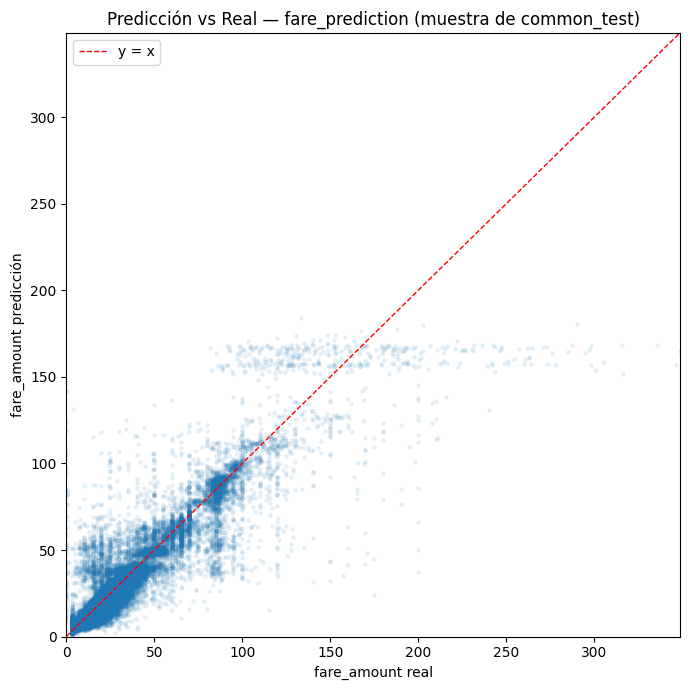

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pdf[LABEL], pdf['prediction'], alpha=0.08, s=6)
lim = float(max(pdf[LABEL].max(), pdf['prediction'].max()))
ax.plot([0, lim], [0, lim], 'r--', linewidth=1, label='y = x')
ax.set_xlabel(f'{LABEL} real')
ax.set_ylabel(f'{LABEL} predicción')
ax.set_title(f'Predicción vs Real — {EXPERIMENT} (muestra de common_test)')
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.legend()
plt.tight_layout()

## 5. Residuos

- Residuo vs predicción: bandas horizontales indican error homocedástico; un embudo, heterocedasticidad.
- Histograma de residuos: debería estar centrado en 0 y ser simétrico. La asimetría indica sobre o infra-predicción sistemática.

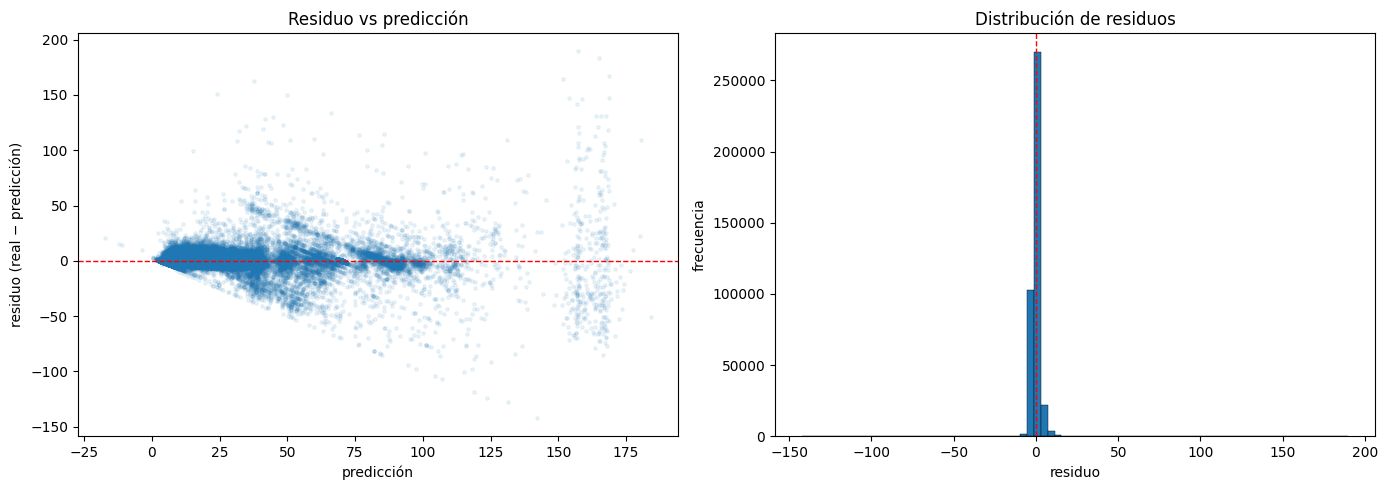

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pdf['prediction'], pdf['residuo'], alpha=0.08, s=6)
axes[0].axhline(0, color='r', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicción')
axes[0].set_ylabel('residuo (real − predicción)')
axes[0].set_title('Residuo vs predicción')
axes[1].hist(pdf['residuo'], bins=80, edgecolor='black', linewidth=0.3)
axes[1].axvline(0, color='r', linestyle='--', linewidth=1)
axes[1].set_xlabel('residuo')
axes[1].set_ylabel('frecuencia')
axes[1].set_title('Distribución de residuos')
plt.tight_layout()

## 6. Importancia de las features

- GBT / RFR: `featureImportances` (reducción media de impureza).
- GLR: `abs(coefficients)`. Las features de GLR están estandarizadas, así que las magnitudes son comparables entre columnas.

,feature,importancia
0,ratecode_id_idx,0.616783
1,trip_distance,0.229006
2,do_location_id_idx,0.063924
3,pu_location_id_idx,0.047706
4,pickup_hour,0.022091
5,pickup_dow,0.010938
6,payment_type_idx,0.004753
7,pickup_week,0.003484
8,vendor_id_idx,0.000874
9,passenger_count,0.000431


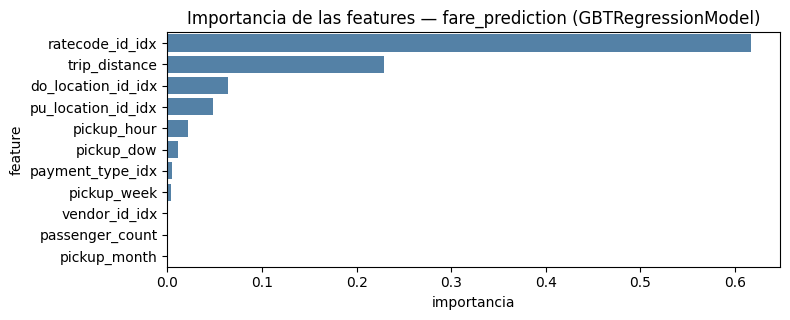

In [10]:
final = model.stages[-1]
algorithm = type(final).__name__
asm = next((s for s in model.stages if isinstance(s, VectorAssembler) and s.getOutputCol() == 'assembled_features'), None)
inputs = list(asm.getInputCols()) if asm is not None else None

if hasattr(final, 'featureImportances'):
    values = final.featureImportances.toArray(); metric_name = 'importancia'
elif hasattr(final, 'coefficients'):
    values = abs(final.coefficients.toArray()); metric_name = 'coef_abs'
else:
    raise RuntimeError(f'El modelo {algorithm} no expone featureImportances ni coefficients')

label_col = 'feature' if inputs is not None and len(inputs) == len(values) else 'feature_idx'
labels = inputs if label_col == 'feature' else list(range(len(values)))
fi = (
    pd.DataFrame({label_col: labels, metric_name: values})
    .sort_values(metric_name, ascending=False)
    .reset_index(drop=True)
)
top = fi.head(30)
display(top)

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(top))))
sns.barplot(data=top, x=metric_name, y=label_col, ax=ax, color='steelblue')
ax.set_title(f'Importancia de las features — {EXPERIMENT} ({algorithm})')
plt.tight_layout()

## 7. Conclusiones — Predicción de tarifa

Modelo `@champion`: `fare_prediction` v2, un GBT (`maxDepth=6`, `maxIter=50`) entrenado sobre 2023–2024. Lectura del diagnóstico:

- Sobreajuste por selección (§3). No hay evidencia: el orden `train` (RMSE 3,46, R² 0,945) ≤ `val` (3,54, 0,942) < `common_test` (3,83, 0,934) es monótono y con saltos pequeños. La brecha `val`→`common_test` (+8,4 % de RMSE) no mide sobreajuste sino el coste de generalizar a un año futuro: `val` sale de 2023–2024 y `common_test` es 2025 íntegro y reservado. La reconstrucción de los splits reproduce los recuentos del entrenamiento (`common_test` exacto, 8.080.072 filas; la frontera `train`/`val` migra 322 filas de 16,3 M ≈ 0,002 % por el no-determinismo de `randomSplit` entre ejecuciones) y el RMSE implícito en la muestra re-puntuada del 5 % (3,82) coincide con el tag registrado (3,835): reproducibilidad verificada.
- Calibración (§4). Bien calibrado en media: residuo medio ≈ −0,02 $ (sin sesgo sistemático); real medio 16,11 $ frente a predicción media 16,13 $. Dos limitaciones del GBT: predice valores negativos en el extremo inferior (mín. −17,3 $, imposible para una tarifa) y comprime la cola alta (predicción máx. 184 $ frente a real 349 $).
- Residuos (§5). Centrados en 0 (mediana −0,21 $), IQR casi simétrico ([−1,16; +0,83] $) y colas pesadas de viajes extremos que el ensemble no ajusta del todo; la dispersión crece con la magnitud (heterocedasticidad leve), coherente con una tarifa positiva y sesgada a la derecha.
- Features (§6). Dominan `ratecode_id` (0,62) y `trip_distance` (0,23), seguidas de las zonas DO/PU (0,06/0,05) y la hora de recogida (0,02). Coincide con el dominio: el código tarifario fija las tarifas planas (JFK, Newark, negociada) y la distancia gobierna la tarifa con taxímetro.
- Coste de inferencia (§2). ~0,99 ms/fila sobre una muestra de 1000 filas de `common_test`: coste de servicio bajo, adecuado para inferencia por lotes.